In [26]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,confusion_matrix, classification_report, ConfusionMatrixDisplay)

In [27]:
df = pd.read_csv("/content/titanic_train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [28]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [29]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [30]:
print("Missing values in each column:")
print(df.isnull().sum())

print()
print("Survival counts:")
print(df["Survived"].value_counts())

Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64


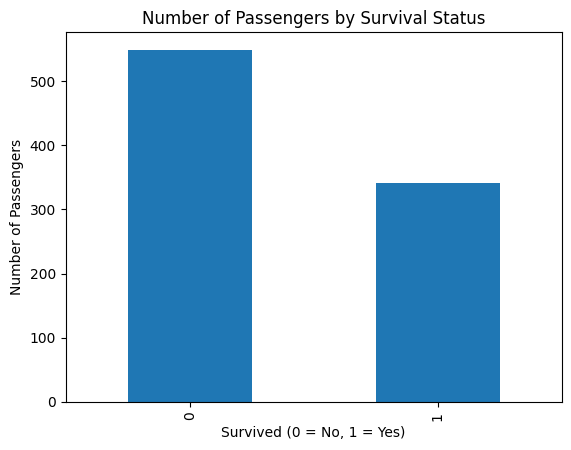

In [31]:
df["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Number of Passengers by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

# Question 4. Handle missing values
Some passengers do not have an age or an embarkation port recorded. We fill missing ages with the median age and missing embarkation ports with the most common port (mode). Median is less affected by unusually high or low values. We do this separately inside the training and test data using a scikit-learn pipeline, so information from the test split does not leak into training.

# Question 5. Encode categorical variables
A machine-learning model needs numbers. Sex and Embarked are text categories, so we use one-hot encoding. It creates numeric columns for categories, such as Sex_male and Sex_female. We keep the original dataset unchanged and let the preprocessing pipeline do this step safely.

# Question 6. Split features (X) and target (y)
X contains the information used to make predictions. y contains the correct answer (Survived). We exclude names, ticket numbers, cabin labels and passenger IDs because they are identifiers or high-cardinality text rather than useful basic predictors for this beginner model.

In [32]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = df[features]
y = df["Survived"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 7)
Target shape: (891,)


In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


In [34]:
y_pred = model.predict(X_test)

print("First 10 actual values:", list(y_test.iloc[:10]))
print("First 10 predicted values:", list(y_pred[:10]))

First 10 actual values: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]
First 10 predicted values: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0)]


In [35]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.827
Precision: 0.817
Recall   : 0.710
F1-score : 0.760

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.86       110
           1       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



Confusion matrix:
[[99 11]
 [20 49]]


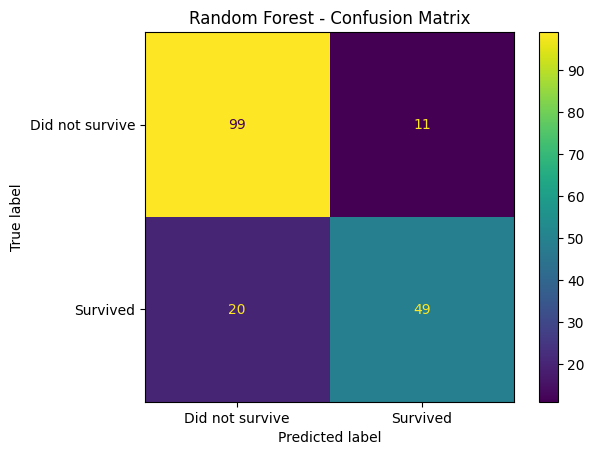

In [36]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Did not survive", "Survived"]).plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

    Feature  Importance
5       Sex    0.288532
2      Fare    0.261052
0       Age    0.254069
4    Pclass    0.077781
6     SibSp    0.046684
1  Embarked    0.036264
3     Parch    0.035620


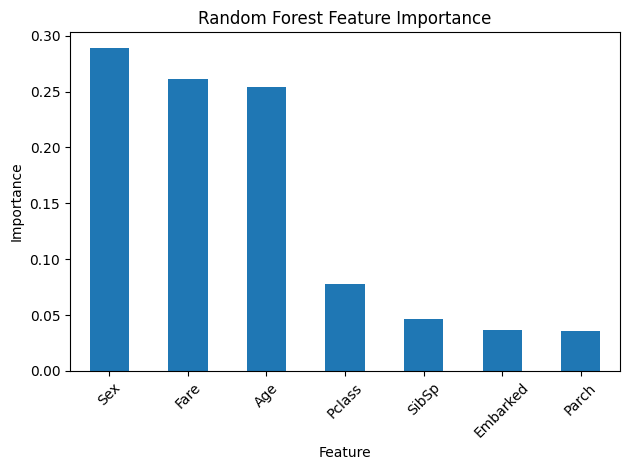

In [37]:
trained_preparation = model.named_steps["preparation"]
encoded_names = trained_preparation.get_feature_names_out()
importance_values = model.named_steps["random_forest"].feature_importances_

importance_table = pd.DataFrame({"Feature": encoded_names,"Importance": importance_values})
importance_table["Feature"] = importance_table["Feature"].str.replace("numbers__", "", regex=False)
importance_table["Feature"] = importance_table["Feature"].str.replace("categories__", "", regex=False)
importance_table["Feature"] = importance_table["Feature"].str.split("_").str[0]
importance_table = importance_table.groupby("Feature", as_index=False)["Importance"].sum()
importance_table = importance_table.sort_values("Importance", ascending=False)

print(importance_table)
importance_table.plot(x="Feature", y="Importance", kind="bar", legend=False)
plt.title("Random Forest Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Conclusion
In this project, i used a real-world passenger dataset to build a Random Forest classification model that predicts the Survived column. I explored the data, checked missing values, filled missing numeric and categorical values, encoded text categories, split the data into training and testing portions, trained the model and evaluated it with accuracy, precision, recall, F1-score and a confusion matrix.